# Empirical Results Analysis

This notebook is the complete path from original run metadata to manuscript tables and figures. It reads raw JSON under the four `Runs*` trees. Outer `RUN_*/run_metadata.json` files identify runs and ordered cycles; each `cicloN/run_metadata.json` contains compiler iterations, LLM calls, stages, and UPPAAL analyses. Output artifacts are written beside this notebook. Operational acceptance means agreement with recorded verification obligations, not independent proof of the informal requirements.

In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
PLOTS = Path.cwd() if Path.cwd().name == "plots" else Path.cwd() / "plots"
ROOT = PLOTS.parent
PLOTS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})
run_files = sorted(p for p in ROOT.glob("Runs*/**/RUN_*/run_metadata.json") if p.parent.name.startswith("RUN_"))
cycle_files = sorted(ROOT.glob("Runs*/**/RUN_*/ciclo*/run_metadata.json"))
print("Root:", ROOT, "| outer files:", len(run_files), "| cycle files:", len(cycle_files))
display(pd.DataFrame({"example files": [str(p.relative_to(ROOT)) for p in run_files[:3] + cycle_files[:3]]}))
print("Outer keys:", sorted(json.loads(run_files[0].read_text()).keys()))
print("Cycle keys:", sorted(json.loads(cycle_files[0].read_text()).keys()))

Root: /Users/livialestingi/PycharmProjects/liras-llm-guided-repair | outer files: 540 | cycle files: 1157


,example files
0,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...
1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...
2,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...
3,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...
4,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...
5,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...


Outer keys: ['abort_reason', 'aborted', 'cycles', 'failed_stage', 'failure_details', 'failure_reason', 'failure_type', 'generation_model', 'generation_provider', 'last_cycle_metadata_path', 'last_cycle_run_dir', 'max_iterations', 'max_uppaal_feedback_cycles', 'overall_result', 'pipeline_runner_version', 'query_provider', 'repair_model', 'repair_prompt', 'repair_provider', 'repair_shots', 'run_dir', 'run_finished_at', 'run_id', 'run_started_at', 'scenario', 'shots', 'system_prompt', 'updated_at']
Cycle keys: ['adapted_query_path', 'block_hf_thinking', 'compiler_dir', 'compiler_jar', 'cycle_result', 'dsl_dir', 'effective_reasoning_effort', 'empty_generation_max_retries', 'empty_query_adaptation_max_retries', 'failed_stage', 'failure_details', 'failure_reason', 'failure_type', 'generated_dsl_cache_path', 'generated_dsl_source', 'generation_attempts', 'generation_max_output_tokens', 'generation_model', 'generation_provider', 'generation_shot_count', 'generation_temperature', 'glm_disable_t

In [2]:
# Shared IEEE figure settings; all lengths are specified at final print size.
IEEE_SINGLE, IEEE_DOUBLE = 3.5, 7.1
FIGURE_SIZE = (IEEE_DOUBLE, 4.0)  # regular manuscript figures
HEATMAP_SIZE = (IEEE_DOUBLE, 2.55)  # Figure 3 keeps its compact, wide layout
PROMPT_COLORS = {"ZS":"#0072B2", "ZS+CoT":"#D55E00", "FS":"#009E73", "FS+CoT":"#CC79A7"}
SCENARIO_COLORS = {"Coffee Delivery":"#0072B2", "User-Guided Transport":"#D55E00", "Factory Pipeline":"#009E73"}
STAGE_COLORS = {"accepted":"#009E73", "dsl_generation":"#595959", "xml_export":"#E69F00", "verifyta_internal":"#0072B2", "query_adaptation":"#CC79A7", "verifyta_adapted":"#D55E00"}
TOKEN_COLORS = {"generate":"#0072B2", "repair":"#E69F00", "query_adaptation":"#CC79A7"}
plt.rcParams.update({
    "font.family":"DejaVu Sans", "font.size":12.5, "axes.titlesize":13.5,
    "axes.labelsize":12.5, "xtick.labelsize":11, "ytick.labelsize":11,
    "legend.fontsize":11, "axes.linewidth":0.85, "lines.linewidth":2.0,
    "pdf.fonttype":42, "svg.fonttype":"none", "savefig.dpi":300,
    "savefig.facecolor":"white", "savefig.bbox":None, "savefig.pad_inches":0, "axes.spines.top":False, "axes.spines.right":False
})
def save_figure(fig, stem, size=FIGURE_SIZE):
    fig.set_size_inches(*size, forward=True)
    for extension in ("pdf","svg"):
        fig.savefig(PLOTS / f"{stem}.{extension}")
    plt.show()
    plt.close(fig)

## A–B. Load and normalize

Run identity uses the source path, never directory iteration order. The outer cycle list is matched to cycle metadata by its local `cicloN` path. Missing or malformed files remain visible as diagnostics. Query rows represent recorded probability intervals and failed query entries, merged by formula index within each cycle and verification path.

In [3]:
def load_json(path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError) as exc:
        return {"_load_error": str(exc)}
outer = {p: load_json(p) for p in run_files}
cycle_raw = {p: load_json(p) for p in cycle_files}
bad_files = [str(p.relative_to(ROOT)) for p, d in {**outer, **cycle_raw}.items() if "_load_error" in d]
print("Malformed/unreadable:", len(bad_files)); display(pd.DataFrame({"file": bad_files}).head(20))
assert not bad_files, "Malformed raw metadata requires investigation"
print("Representative run:", {k: outer[run_files[0]].get(k) for k in ("run_id", "scenario", "shots", "overall_result", "successful_cycle")})
print("Representative cycle:", {k: cycle_raw[cycle_files[0]].get(k) for k in ("pipeline_cycle", "cycle_result", "failed_stage", "status")})

Malformed/unreadable: 0


,file


Representative run: {'run_id': '20260724_200426', 'scenario': 'NL_Specification_1.txt', 'shots': 'leave_one_spec_out', 'overall_result': 'failed', 'successful_cycle': None}
Representative cycle: {'pipeline_cycle': 1, 'cycle_result': 'failed', 'failed_stage': 'verifyta_internal', 'status': 'success'}


In [4]:
SCENARIOS = {"NL_Specification_1.txt": "Coffee Delivery", "NL_Specification_2.txt": "User-Guided Transport", "NL_Specification_3.txt": "Factory Pipeline"}
PROMPTS = {"RunsNoCoT": "ZS", "RunsCoT": "ZS+CoT", "Runs2ShotNoCoT": "FS", "Runs2ShotCoT": "FS+CoT"}
MODEL_LABELS = {"Qwen3.5-9B": "Qwen3.5-9B", "Qwen3.6-35B-A3B": "Qwen3.6-35B-A3B", "gemma-4-31B-it": "Gemma 4 31B IT", "GLM-5.2": "GLM-5.2", "gpt-oss-20b": "gpt-oss-20b"}
run_rows, cycle_rows, call_rows, query_rows, iteration_rows, missing_cycles = [], [], [], [], [], []
for path, run in outer.items():
    rel = path.relative_to(ROOT)
    prompt, model_dir = rel.parts[:2]
    run_key = str(rel.parent)
    run_rows.append({"run_key": run_key, "source_file": str(rel), "run_id": run.get("run_id"), "scenario": SCENARIOS.get(run.get("scenario"), run.get("scenario")), "model": MODEL_LABELS.get(model_dir, model_dir), "prompt": PROMPTS.get(prompt, prompt), "shots": run.get("shots"), "overall_result": run.get("overall_result"), "recorded_success_cycle": run.get("successful_cycle"), "recorded_failed_stage": run.get("failed_stage"), "max_cycles": run.get("max_uppaal_feedback_cycles"), "max_iterations": run.get("max_iterations"), "started_at": run.get("run_started_at"), "finished_at": run.get("run_finished_at")})
    for cr in run.get("cycles", []):
        n = cr.get("cycle")
        cp = path.parent / f"ciclo{n}" / "run_metadata.json"
        meta = cycle_raw.get(cp)
        if meta is None:
            missing_cycles.append({"run_key": run_key, "cycle": n, "expected_file": str(cp.relative_to(ROOT))})
            meta = {}
        stages = {s.get("stage"): s for s in cr.get("stages", [])}
        cycle_rows.append({"run_key": run_key, "cycle": n, "source_file": str(cp.relative_to(ROOT)) if cp.exists() else None, "cycle_result": cr.get("cycle_result"), "failed_stage": cr.get("failed_stage"), "failure_type": cr.get("failure_type"), "continue_feedback_loop": cr.get("continue_feedback_loop"), "compiler_ok": stages.get("dsl_generation", {}).get("result") == "ok", "export_ok": stages.get("xml_export", {}).get("result") == "ok", "internal_ok": stages.get("verifyta_internal", {}).get("result") == "ok", "adaptation_ok": stages.get("query_adaptation", {}).get("result") == "ok", "scenario_ok": stages.get("verifyta_adapted", {}).get("result") == "ok", "recorded_internal_count": (meta.get("verifyta_internal_analysis") or {}).get("verified_formula_count"), "recorded_scenario_count": (meta.get("verifyta_adapted_analysis") or {}).get("verified_formula_count"), "threshold": meta.get("verifyta_probability_delta_threshold"), "started_at": meta.get("run_started_at"), "finished_at": meta.get("run_finished_at")})
        for it in meta.get("iterations", []):
            iteration_rows.append({"run_key": run_key, "cycle": n, "iteration": it.get("iteration"), "is_valid": it.get("is_valid"), "validated": it.get("validated"), "returncode": (it.get("validation") or {}).get("returncode")})
        for j, call in enumerate(meta.get("llm_call_history", [])):
            call_rows.append({"run_key": run_key, "cycle": n, "call_index": j, "source_file": str(cp.relative_to(ROOT)), "kind": call.get("kind"), "provider": call.get("provider"), "timestamp": call.get("timestamp"), "finish_reason": call.get("finish_reason"), "input_tokens": call.get("prompt_tokens"), "output_tokens": call.get("completion_tokens"), "reasoning_tokens": call.get("reasoning_tokens"), "total_tokens": call.get("total_tokens"), "usage_available": call.get("token_usage_available")})
        for verification_path, field in (("internal", "verifyta_internal_analysis"), ("scenario", "verifyta_adapted_analysis")):
            analysis = meta.get(field) or {}
            entries = {}
            for kind, records in (("interval", analysis.get("probability_checked_queries") or []), ("failure", analysis.get("failed_queries") or [])):
                for j, record in enumerate(records):
                    key = record.get("index") if record.get("index") is not None else f"unindexed_{kind}_{j}"
                    entries.setdefault(key, {}).update(record)
                    entries[key]["has_interval"] = entries[key].get("has_interval", False) or kind == "interval"
                    entries[key]["has_failure"] = entries[key].get("has_failure", False) or kind == "failure"
            for key, record in entries.items():
                lo, hi, ref = (record.get(k) for k in ("probability_interval_lower", "probability_interval_upper", "expected_probability"))
                measured = all(isinstance(v, (int, float)) for v in (lo, hi, ref)) and record.get("has_interval", False)
                deviation = abs((lo + hi) / 2 - ref) if measured else np.nan
                failure = record.get("failure_kind")
                status = failure or ("mismatch" if measured and deviation > .05 else "pass" if measured else "incomplete")
                query_rows.append({"run_key": run_key, "cycle": n, "verification_path": verification_path, "query_index": key, "source_file": str(cp.relative_to(ROOT)), "source_formula": record.get("source_formula"), "adapted_formula": record.get("adapted_formula"), "reference": ref, "lower": lo, "upper": hi, "midpoint": (lo + hi)/2 if measured else np.nan, "measured_deviation": deviation, "recorded_delta": record.get("probability_delta"), "status": status, "failure_kind": failure, "has_interval": record.get("has_interval", False), "has_failure": record.get("has_failure", False)})
runs_df = pd.DataFrame(run_rows); cycles_df = pd.DataFrame(cycle_rows); llm_calls_df = pd.DataFrame(call_rows); queries_df = pd.DataFrame(query_rows); iterations_df = pd.DataFrame(iteration_rows)
for name, frame in (("runs", runs_df), ("cycles", cycles_df), ("llm calls", llm_calls_df), ("queries", queries_df), ("compiler iterations", iterations_df)):
    print(name, frame.shape, list(frame.columns)); display(frame.head(2))
print("Missing linked cycle metadata:", len(missing_cycles)); display(pd.DataFrame(missing_cycles).head(20))

runs (540, 14) ['run_key', 'source_file', 'run_id', 'scenario', 'model', 'prompt', 'shots', 'overall_result', 'recorded_success_cycle', 'recorded_failed_stage', 'max_cycles', 'max_iterations', 'started_at', 'finished_at']


,run_key,source_file,run_id,scenario,model,prompt,shots,overall_result,recorded_success_cycle,recorded_failed_stage,max_cycles,max_iterations,started_at,finished_at
0,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,20260724_200426,Coffee Delivery,GLM-5.2,FS+CoT,leave_one_spec_out,failed,NaN,verifyta_internal,5,11,2026-07-24T20:04:26.435162,2026-07-24T20:11:34.340841
1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,20260724_201134,Coffee Delivery,GLM-5.2,FS+CoT,leave_one_spec_out,failed,NaN,verifyta_internal,5,11,2026-07-24T20:11:34.342011,2026-07-24T20:16:11.777164


cycles (1157, 17) ['run_key', 'cycle', 'source_file', 'cycle_result', 'failed_stage', 'failure_type', 'continue_feedback_loop', 'compiler_ok', 'export_ok', 'internal_ok', 'adaptation_ok', 'scenario_ok', 'recorded_internal_count', 'recorded_scenario_count', 'threshold', 'started_at', 'finished_at']


,run_key,cycle,source_file,cycle_result,failed_stage,failure_type,continue_feedback_loop,compiler_ok,export_ok,internal_ok,adaptation_ok,scenario_ok,recorded_internal_count,recorded_scenario_count,threshold,started_at,finished_at
0,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,failed,verifyta_internal,execution,True,True,True,False,True,False,14.0,16.0,0.05,2026-07-24T20:04:26.440887,2026-07-24T20:04:56.893687
1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,2,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,failed,verifyta_internal,execution,True,True,True,False,True,False,14.0,16.0,0.05,2026-07-24T20:06:16.256547,2026-07-24T20:06:41.788343


llm calls (2782, 13) ['run_key', 'cycle', 'call_index', 'source_file', 'kind', 'provider', 'timestamp', 'finish_reason', 'input_tokens', 'output_tokens', 'reasoning_tokens', 'total_tokens', 'usage_available']


...

,run_key,cycle,verification_path,query_index,source_file,source_formula,adapted_formula,reference,lower,upper,midpoint,measured_deviation,recorded_delta,status,failure_kind,has_interval,has_failure
0,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,1,internal,1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,,,NaN,NaN,NaN,NaN,NaN,NaN,aborted,aborted,False,True
1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,1,internal,2,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,,,NaN,NaN,NaN,NaN,NaN,NaN,aborted,aborted,False,True


compiler iterations (1716, 6) ['run_key', 'cycle', 'iteration', 'is_valid', 'validated', 'returncode']


,run_key,cycle,iteration,is_valid,validated,returncode
0,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,1,0,True,True,0.0
1,Runs2ShotCoT/GLM-5.2/NL_Specification_1/Genera...,2,0,True,True,0.0


Missing linked cycle metadata: 0


""


### Response-log call accounting

Cycle `llm_call_history` records token usage, but some completed repair responses are absent from that history. The raw `llm_responses.jsonl` files are the authoritative count of completed responses. This cell matches history usage to response entries by kind and timestamp within each cycle. Unmatched responses remain calls with missing token usage; their cost is never replaced by zero.

In [5]:
call_history_df = llm_calls_df.copy()
response_rows, malformed_response_lines = [], []
for p, meta in cycle_raw.items():
    run_key = str(p.parent.parent.relative_to(ROOT))
    cycle = int(p.parent.name.removeprefix("ciclo"))
    log_path = p.parent / "llm_responses.jsonl"
    if not log_path.exists():
        continue
    history = call_history_df[(call_history_df.run_key == run_key) & (call_history_df.cycle == cycle)]
    unmatched = set(history.index)
    for j, line in enumerate(log_path.read_text(encoding="utf-8").splitlines()):
        try:
            response = json.loads(line)
        except json.JSONDecodeError as exc:
            malformed_response_lines.append({"source_file":str(log_path.relative_to(ROOT)),"line":j+1,"error":str(exc)})
            continue
        stamp = pd.to_datetime(response.get("timestamp"), errors="coerce")
        candidates = history.loc[list(unmatched)]
        candidates = candidates[candidates.kind.eq(response.get("kind"))]
        if not candidates.empty and pd.notna(stamp):
            distances = (pd.to_datetime(candidates.timestamp, errors="coerce") - stamp).abs().dt.total_seconds()
            match = distances.idxmin() if distances.notna().any() and distances.min() <= 5 else None
        else:
            match = None
        usage = history.loc[match] if match is not None else None
        if match is not None:
            unmatched.remove(match)
        response_rows.append({"run_key":run_key,"cycle":cycle,"call_index":j,"source_file":str(log_path.relative_to(ROOT)),"kind":response.get("kind"),"provider":response.get("provider"),"timestamp":response.get("timestamp"),"finish_reason":response.get("finish_reason"),"attempt":response.get("attempt"),"input_tokens":usage.input_tokens if usage is not None else np.nan,"output_tokens":usage.output_tokens if usage is not None else np.nan,"reasoning_tokens":usage.reasoning_tokens if usage is not None else np.nan,"total_tokens":usage.total_tokens if usage is not None else np.nan,"usage_available":bool(usage.usage_available) if usage is not None else False,"matched_history":match is not None})
    if unmatched:
        warnings.warn(f"{len(unmatched)} history calls lack a response-log match: {p.relative_to(ROOT)}")
llm_calls_df = pd.DataFrame(response_rows)
print("Response-log calls:",len(llm_calls_df),"matched usage:",int(llm_calls_df.matched_history.sum()),"unmatched completed responses:",int((~llm_calls_df.matched_history).sum()))
print("Malformed response lines:",len(malformed_response_lines)); display(pd.DataFrame(malformed_response_lines).head(20))
display(llm_calls_df.groupby(["kind","matched_history"]).size().rename("calls").reset_index())
display(llm_calls_df.loc[~llm_calls_df.matched_history,["source_file","call_index","kind","attempt"]].head(20))
assert not malformed_response_lines
assert llm_calls_df.matched_history.sum() == len(call_history_df)

Response-log calls: 3099 matched usage: 2782 unmatched completed responses: 317
Malformed response lines: 0


""


,kind,matched_history,calls
0,generate,True,1160
1,query_adaptation,True,1063
2,repair,False,317
3,repair,True,559


,source_file,call_index,kind,attempt
809,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,4,repair,0.0
811,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,6,repair,0.0
813,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,8,repair,0.0
815,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,10,repair,0.0
816,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,11,repair,1.0
843,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,4,repair,0.0
844,Runs2ShotNoCoT/GLM-5.2/NL_Specification_1/Gene...,5,repair,1.0
905,Runs2ShotNoCoT/GLM-5.2/NL_Specification_2/Gene...,3,repair,1.0
907,Runs2ShotNoCoT/GLM-5.2/NL_Specification_2/Gene...,5,repair,1.0
919,Runs2ShotNoCoT/GLM-5.2/NL_Specification_2/Gene...,2,repair,0.0


## C–D. Workflow outcomes and verification

The runner accepts a cycle only after successful DSL compilation, XML export, internal UPPAAL verification, query adaptation, and adapted scenario verification. Compiler repair is an iteration within a cycle; verification feedback starts a later cycle. Export failure has no exporter-specific repair loop. A query interval is measured only when both bounds and a reference exist. For those entries the notebook recomputes \(\widetilde p=(l+u)/2\) and \(\Delta=|\widetilde p-p^{ref}|\); a successful check passes at \(\Delta\leq0.05\). Aborted and error entries with recorded delta 1.0 are classified by their failure kind, never as measured differences.

In [6]:
assert runs_df.run_key.is_unique
assert not cycles_df.duplicated(["run_key", "cycle"]).any()
assert cycles_df.groupby("run_key").cycle.apply(lambda s: list(s) == list(range(1, len(s)+1))).all()
assert cycles_df.cycle.between(1, 5).all()
assert not missing_cycles
assert not llm_calls_df.duplicated(["run_key", "cycle", "call_index"]).any()
assert not queries_df.duplicated(["run_key", "cycle", "verification_path", "query_index"]).any()
assert runs_df.max_cycles.eq(5).all()
assert runs_df.max_iterations.eq(11).all()  # initial candidate plus ten repairs
assert cycles_df.threshold.dropna().eq(.05).all()
assert iterations_df.iteration.dropna().between(0, 10).all()
assert queries_df.loc[queries_df.has_interval & queries_df.reference.notna(), "measured_deviation"].notna().all()
stage_order = ["dsl_generation", "xml_export", "verifyta_internal", "query_adaptation", "verifyta_adapted"]
def reconstructed_stage(row):
    flags = [row.compiler_ok, row.export_ok, row.internal_ok, row.adaptation_ok, row.scenario_ok]
    return "accepted" if all(flags) else stage_order[flags.index(False)]
cycles_df["reconstructed_stage"] = cycles_df.apply(reconstructed_stage, axis=1)
cycles_df["reconstructed_accepted"] = cycles_df.reconstructed_stage.eq("accepted")
cycles_df["initial_candidate_accepted"] = cycles_df.reconstructed_accepted & cycles_df.set_index(["run_key","cycle"]).index.map(lambda key: bool(iterations_df[(iterations_df.run_key == key[0]) & (iterations_df.cycle == key[1]) & (iterations_df.iteration == 0)].is_valid.any()))
cycle_discrepancies = cycles_df.loc[cycles_df.reconstructed_accepted.ne(cycles_df.cycle_result.eq("ok")) | ((cycles_df.failed_stage.notna()) & cycles_df.reconstructed_stage.ne(cycles_df.failed_stage))]
print("Cycle outcome discrepancies:", len(cycle_discrepancies)); display(cycle_discrepancies.head(20))
last_cycles = cycles_df.sort_values("cycle").groupby("run_key").tail(1)[["run_key","reconstructed_stage"]].rename(columns={"reconstructed_stage":"terminal_stage"})
accept_cycle = cycles_df[cycles_df.reconstructed_accepted].groupby("run_key").cycle.min().rename("accept_cycle")
initial = cycles_df[cycles_df.initial_candidate_accepted].groupby("run_key").cycle.min().rename("initial_cycle")
runs_df = runs_df.merge(last_cycles, on="run_key", validate="one_to_one").merge(accept_cycle, on="run_key", how="left", validate="one_to_one").merge(initial, on="run_key", how="left", validate="one_to_one")
runs_df["accepted"] = runs_df.accept_cycle.notna()
runs_df["initial_accepted"] = runs_df.initial_cycle.eq(1)
runs_df["terminal_group"] = runs_df.terminal_stage.replace({"dsl_generation":"generation/compilation","xml_export":"export","verifyta_internal":"verification","query_adaptation":"verification","verifyta_adapted":"verification"})
run_discrepancies = runs_df.loc[runs_df.accepted.ne(runs_df.overall_result.eq("ok")) | (runs_df.accept_cycle.fillna(-1).ne(runs_df.recorded_success_cycle.fillna(-1)))]
print("Run outcome discrepancies:", len(run_discrepancies)); display(run_discrepancies.head(20))
print("Terminal stage counts:"); display(runs_df.terminal_group.value_counts(dropna=False).rename_axis("outcome").to_frame("runs"))
print("Query status counts:"); display(queries_df.groupby(["verification_path","status"]).size().rename("occurrences").reset_index())
print("Sentinel failures:", int(queries_df.loc[queries_df.has_failure & ~queries_df.has_interval, "recorded_delta"].eq(1).sum()))
assert len(cycle_discrepancies) == 0 and len(run_discrepancies) == 0
assert runs_df.accepted.sum() + (~runs_df.accepted).sum() == len(runs_df)

Cycle outcome discrepancies: 0


,run_key,cycle,source_file,cycle_result,failed_stage,failure_type,continue_feedback_loop,compiler_ok,export_ok,internal_ok,adaptation_ok,scenario_ok,recorded_internal_count,recorded_scenario_count,threshold,started_at,finished_at,reconstructed_stage,reconstructed_accepted,initial_candidate_accepted


Run outcome discrepancies: 0


,run_key,source_file,run_id,scenario,model,prompt,shots,overall_result,recorded_success_cycle,recorded_failed_stage,max_cycles,max_iterations,started_at,finished_at,terminal_stage,accept_cycle,initial_cycle,accepted,initial_accepted,terminal_group


Terminal stage counts:


,runs
outcome,
accepted,319
verification,127
export,61
generation/compilation,33


Query status counts:


,verification_path,status,occurrences
0,internal,aborted,5275
1,internal,verifyta_error,12
2,scenario,aborted,5383
3,scenario,pass,10787
4,scenario,probability_delta,120
5,scenario,verifyta_error,181


Sentinel failures: 5383


## Detailed verification cross-check

The cycle metadata also stores per-path analyses. The following check compares their status and individual failed-query records with the stage flags, and tests every available interval against the recorded midpoint. Only completed adapted checks with an interval can provide a measured deviation. The adapted formulas themselves may differ from the original source formulas, so operational acceptance should not be read as independent requirements correctness.

Six entries contain both a valid interval and a verifier-error sentinel at the same formula index. Their interval midpoint is independently measurable, but the recorded failure delta of 1.0 is a sentinel. The diagnostic cell displays the affected source records.

In [7]:
analysis_rows = []
for p, d in cycle_raw.items():
    for path, key in (("internal","verifyta_internal_analysis"),("scenario","verifyta_adapted_analysis")):
        a = d.get(key)
        if a is None:
            continue
        analysis_rows.append({"source_file":str(p.relative_to(ROOT)),"path":path,"status":a.get("status"),"verified":a.get("verified_formula_count"),"failed_recorded":a.get("failed_query_count"),"failed_list":len(a.get("failed_queries") or []),"intervals_recorded":a.get("probability_checked_query_count"),"interval_list":len(a.get("probability_checked_queries") or [])})
analyses_df = pd.DataFrame(analysis_rows)
analyses_df["run_key"] = analyses_df.source_file.str.replace(r"/ciclo[0-9]+/run_metadata.json$", "", regex=True)
analyses_df["cycle"] = analyses_df.source_file.str.extract(r"/ciclo([0-9]+)/").astype(int)
analyses_df = analyses_df.merge(cycles_df[["run_key","cycle","internal_ok","scenario_ok"]],on=["run_key","cycle"],validate="many_to_one")
analyses_df["stage_ok"] = np.where(analyses_df.path.eq("internal"),analyses_df.internal_ok,analyses_df.scenario_ok)
analyses_df["recomputed_ok"] = analyses_df.failed_list.eq(0) & analyses_df.apply(lambda r: not queries_df[(queries_df.source_file == r.source_file) & (queries_df.verification_path == r.path)].measured_deviation.gt(.05).any(), axis=1)
analysis_discrepancies = analyses_df[(analyses_df.failed_recorded != analyses_df.failed_list) | (analyses_df.intervals_recorded != analyses_df.interval_list) | (analyses_df.status.eq("ok") != analyses_df.stage_ok) | (analyses_df.recomputed_ok != analyses_df.stage_ok)]
print("Analysis/stage/count discrepancies:",len(analysis_discrepancies)); display(analysis_discrepancies.head(20))
intervals = queries_df[queries_df.has_interval & queries_df.reference.notna()].copy()
intervals["delta_discrepancy"] = (intervals.measured_deviation - intervals.recorded_delta).abs()
print("Measured intervals:",len(intervals),"recorded delta disagreement > 1e-6:",int(intervals.delta_discrepancy.gt(1e-6).sum()))
print(intervals.loc[intervals.delta_discrepancy.gt(1e-6), ["source_file","query_index","midpoint","reference","measured_deviation","recorded_delta","failure_kind"]].to_string(index=False))
print("Interval rows with failure kind:",int(intervals.has_failure.sum()))
print("Unlinked cycle files:",len(set(cycle_files)-{p.parent / f"ciclo{c.get('cycle')}" / "run_metadata.json" for p,r in outer.items() for c in r.get("cycles",[])}))
assert len(analysis_discrepancies) == 0
assert not intervals.loc[~intervals.failure_kind.eq("verifyta_error"),"delta_discrepancy"].gt(1e-6).any()
assert intervals.loc[intervals.delta_discrepancy.gt(1e-6),"failure_kind"].eq("verifyta_error").all()

Analysis/stage/count discrepancies: 0


,source_file,path,status,verified,failed_recorded,failed_list,intervals_recorded,interval_list,run_key,cycle,internal_ok,scenario_ok,stage_ok,recomputed_ok


Measured intervals: 10913 recorded delta disagreement > 1e-6: 6
                                                                                                   source_file query_index  midpoint  reference  measured_deviation  recorded_delta   failure_kind
   Runs2ShotNoCoT/GLM-5.2/NL_Specification_3/Generative/NewSP8.j2/RUN_20260724_160411/ciclo1/run_metadata.json          14  0.024972   0.024972                 0.0             1.0 verifyta_error
Runs2ShotNoCoT/Qwen3.5-9B/NL_Specification_3/Generative/NewSP8.j2/RUN_20260724_160919/ciclo4/run_metadata.json          16  0.024972   0.024972                 0.0             1.0 verifyta_error
Runs2ShotNoCoT/Qwen3.5-9B/NL_Specification_3/Generative/NewSP8.j2/RUN_20260724_160919/ciclo5/run_metadata.json          16  0.024972   0.024972                 0.0             1.0 verifyta_error
Runs2ShotNoCoT/Qwen3.5-9B/NL_Specification_3/Generative/NewSP8.j2/RUN_20260724_163427/ciclo1/run_metadata.json          14  0.024972   0.024972             

## RQ1 — Acceptance and terminal failures

Acceptance uses all ten recorded repetitions in each tested configuration. A run has exactly one terminal outcome. The post compilation failure fraction divides export and verification terminations by all unsuccessful runs.

In [8]:
scenario_outcomes = runs_df.groupby(["scenario","terminal_group"]).size().unstack(fill_value=0).reindex(columns=["accepted","generation/compilation","export","verification"], fill_value=0)
scenario_outcomes["total"] = scenario_outcomes.sum(axis=1)
scenario_outcomes["acceptance_pct"] = 100 * scenario_outcomes["accepted"] / scenario_outcomes["total"]
overall_outcomes = runs_df.terminal_group.value_counts().reindex(["accepted","generation/compilation","export","verification"], fill_value=0)
post_compile_fraction = (overall_outcomes["export"] + overall_outcomes["verification"]) / (len(runs_df) - runs_df.accepted.sum())
display(scenario_outcomes)
print("Overall acceptance:", f"{runs_df.accepted.sum()}/{len(runs_df)}", "post-compilation failure fraction:", f"{post_compile_fraction:.1%}")
assert scenario_outcomes.total.sum() == len(runs_df)
scenario_outcomes.to_latex(PLOTS / "table_final_outcomes.tex", float_format="%.1f")

terminal_group,accepted,generation/compilation,export,verification,total,acceptance_pct
scenario,,,,,,
Coffee Delivery,55,25,5,95,180,30.555556
Factory Pipeline,167,3,3,7,180,92.777778
User-Guided Transport,97,5,53,25,180,53.888889


Overall acceptance: 319/540 post-compilation failure fraction: 85.1%


## RQ2 — Recovery checkpoints

Each cumulative rate uses the fixed number of runs in its prompting group. A run that stops before a later checkpoint remains in the denominator. Initial candidate means the first DSL candidate compiled and its first cycle passed both verification paths. Later increments are descriptive observations; checkpoint differences do not isolate a causal feedback effect.

In [9]:
checkpoint_rows = []
for prompt, subset in runs_df.groupby("prompt"):
    denominator = len(subset)
    previous = 0
    for label, cutoff in [("Initial", 0), ("Cycle 1", 1), ("Cycle 2", 2), ("Cycle 3", 3), ("Cycle 4", 4), ("Cycle 5", 5)]:
        accepted = int(subset.initial_accepted.sum()) if cutoff == 0 else int(subset.accept_cycle.le(cutoff).sum())
        reached = denominator if cutoff == 0 else int(cycles_df[(cycles_df.run_key.isin(subset.run_key)) & (cycles_df.cycle == cutoff)].shape[0])
        checkpoint_rows.append({"prompt": prompt, "checkpoint": label, "runs": denominator, "reached": reached, "cumulative": accepted, "additional": accepted - previous, "acceptance_pct": 100*accepted/denominator})
        previous = accepted
recovery_df = pd.DataFrame(checkpoint_rows)
display(recovery_df)
display(recovery_df.groupby("checkpoint")[["reached","cumulative","additional"]].sum().reindex(["Initial","Cycle 1","Cycle 2","Cycle 3","Cycle 4","Cycle 5"]))
assert recovery_df.query("checkpoint == 'Cycle 5'").cumulative.sum() == runs_df.accepted.sum()
recovery_df.to_latex(PLOTS / "table_recovery.tex", index=False, float_format="%.1f")

,prompt,checkpoint,runs,reached,cumulative,additional,acceptance_pct
0,FS,Initial,120,120,44,44,36.666667
1,FS,Cycle 1,120,120,53,9,44.166667
2,FS,Cycle 2,120,48,60,7,50.000000
3,FS,Cycle 3,120,37,64,4,53.333333
4,FS,Cycle 4,120,33,66,2,55.000000
5,FS,Cycle 5,120,31,66,0,55.000000
6,FS+CoT,Initial,150,150,71,71,47.333333
7,FS+CoT,Cycle 1,150,150,73,2,48.666667
8,FS+CoT,Cycle 2,150,64,81,8,54.000000
9,FS+CoT,Cycle 3,150,55,83,2,55.333333


,reached,cumulative,additional
checkpoint,,,
Initial,540,233,233
Cycle 1,540,267,34
Cycle 2,190,295,28
Cycle 3,155,307,12
Cycle 4,141,316,9
Cycle 5,131,319,3


## RQ3 — Configuration sensitivity

Cells report accepted and total runs; untested combinations are unavailable. Full matrix prompt aggregates have unequal model coverage because gpt-oss-20b was tested only with CoT. The shared-model aggregate removes that coverage difference. Neither aggregate isolates CoT or few-shot effects from all other configuration differences.

In [10]:
scenario_order = ["Coffee Delivery","User-Guided Transport","Factory Pipeline"]
model_order = ["Qwen3.5-9B","Qwen3.6-35B-A3B","Gemma 4 31B IT","GLM-5.2","gpt-oss-20b"]
prompt_order = ["ZS","ZS+CoT","FS","FS+CoT"]
config_counts = runs_df.groupby(["scenario","model","prompt"]).accepted.agg(accepted="sum", total="count")
all_cells = pd.MultiIndex.from_product([scenario_order,model_order,prompt_order], names=["scenario","model","prompt"])
config_table = config_counts.reindex(all_cells).reset_index()
config_table["accepted/total"] = config_table.apply(lambda r: "—" if pd.isna(r.total) else f"{int(r.accepted)}/{int(r.total)}", axis=1)
config_table["acceptance_pct"] = 100*config_table.accepted/config_table.total
display(config_table.pivot(index=["scenario","model"], columns="prompt", values="accepted/total"))
print("Tested configurations:", config_table.total.notna().sum(), "unavailable:", config_table.total.isna().sum())
matrix_table = config_table.pivot(index=["scenario","model"], columns="prompt", values="accepted/total")
matrix_table.to_latex(PLOTS / "table_experimental_matrix.tex")
config_table.to_latex(PLOTS / "table_configuration_acceptance.tex", index=False, float_format="%.1f")
prompt_full = runs_df.groupby("prompt").accepted.agg(accepted="sum", total="count").reindex(prompt_order)
shared_models = set(model_order) - {"gpt-oss-20b"}
prompt_shared = runs_df[runs_df.model.isin(shared_models)].groupby("prompt").accepted.agg(accepted="sum", total="count").reindex(prompt_order)
for t in (prompt_full,prompt_shared):
    t["acceptance_pct"] = 100*t.accepted/t.total
print("Full matrix:"); display(prompt_full)
print("Four shared models:"); display(prompt_shared)
assert config_table.total.dropna().eq(10).all()
assert config_table.total.sum() == len(runs_df)

prompt                                    FS FS+CoT     ZS ZS+CoT
scenario              model                                      
Coffee Delivery       GLM-5.2           0/10   0/10   0/10  10/10
                      Gemma 4 31B IT    0/10   0/10   0/10  10/10
                      Qwen3.5-9B        1/10   3/10   1/10   9/10
                      Qwen3.6-35B-A3B   1/10   0/10   1/10   9/10
                      gpt-oss-20b          —   0/10      —  10/10
Factory Pipeline      GLM-5.2          10/10  10/10  10/10   8/10
                      Gemma 4 31B IT   10/10  10/10  10/10  10/10
                      Qwen3.5-9B        9/10  10/10   9/10  10/10
                      Qwen3.6-35B-A3B   9/10  10/10   4/10   8/10
                      gpt-oss-20b          —  10/10      —  10/10
User-Guided Transport GLM-5.2           5/10   6/10   6/10   8/10
                      Gemma 4 31B IT   10/10  10/10   3/10   0/10
                      Qwen3.5-9B        2/10   3/10   1/10   4/10
                      Qwen3.6-35B-A3B   9/10   4/10   5/10   3/10
                      gpt-oss-20b          —   9/10      —   9/10

Tested configurations: 54 unavailable: 6
Full matrix:


,accepted,total,acceptance_pct
prompt,,,
ZS,50,120,41.666667
ZS+CoT,118,150,78.666667
FS,66,120,55.000000
FS+CoT,85,150,56.666667


Four shared models:


,accepted,total,acceptance_pct
prompt,,,
ZS,50,120,41.666667
ZS+CoT,89,120,74.166667
FS,66,120,55.000000
FS+CoT,66,120,55.000000


## RQ4 — Effort and failure occurrences

Completed calls are counted from `llm_responses.jsonl`, with generation and compiler repair grouped separately from query adaptation. Token usage is attached from matching cycle `llm_call_history` entries. Reported completion tokens are output tokens; provider reasoning tokens, where separately exposed, are a component of output rather than an extra charge. Recorded output tokens per accepted run divide the sum of available usage across all runs, including failed runs, by accepted runs. Because 317 completed repair responses lack usage, these ratios are lower bounds, not full expenditure. Query failures count occurrences, independently of terminal run failures. Duration is the outer run's recorded finish minus start time.

In [11]:
llm_calls_df["effort_type"] = np.where(llm_calls_df.kind.eq("query_adaptation"), "query adaptation", "generation/repair")
llm_calls_df["reasoning_tokens"] = pd.to_numeric(llm_calls_df.reasoning_tokens, errors="coerce")
runs_df["duration_s"] = (pd.to_datetime(runs_df.finished_at, errors="coerce") - pd.to_datetime(runs_df.started_at, errors="coerce")).dt.total_seconds()
run_effort = llm_calls_df.pivot_table(index="run_key", columns="effort_type", values=["input_tokens","output_tokens"], aggfunc="sum", fill_value=0)
run_effort.columns = ["_".join(x).replace(" ","_").replace("/","_") for x in run_effort.columns]
run_effort = run_effort.reset_index()
run_call_counts = llm_calls_df.groupby(["run_key","kind"]).size().unstack(fill_value=0).reset_index()
effort_runs = runs_df.merge(run_effort,on="run_key",how="left",validate="one_to_one").merge(run_call_counts,on="run_key",how="left",validate="one_to_one")
effort_runs["executed_cycles"] = effort_runs.run_key.map(cycles_df.groupby("run_key").size())
for col in ["generate","repair","query_adaptation"]:
    effort_runs[col] = effort_runs[col].fillna(0).astype(int)
effort_runs["generation_repair_calls"] = effort_runs.generate + effort_runs.repair
effort_runs["unmetered_repair_calls"] = effort_runs.run_key.map(llm_calls_df[llm_calls_df.kind.eq("repair") & ~llm_calls_df.usage_available].groupby("run_key").size()).fillna(0).astype(int)
output_col = "output_tokens_generation_repair"
query_output_col = "output_tokens_query_adaptation"
effort_table = effort_runs.groupby("prompt").agg(runs=("run_key","size"), accepted=("accepted","sum"), cycles=("executed_cycles","sum"), generation_calls=("generate","sum"), repair_calls=("repair","sum"), unmetered_repair_calls=("unmetered_repair_calls","sum"), query_calls=("query_adaptation","sum"), recorded_generation_output=(output_col,"sum"), query_output=(query_output_col,"sum"), median_duration_s=("duration_s","median")).reindex(prompt_order)
effort_table["output_per_accepted"] = effort_table.recorded_generation_output / effort_table.accepted
display(effort_table)
shared_effort = effort_runs[effort_runs.model.isin(shared_models)].groupby("prompt").agg(accepted=("accepted","sum"), unmetered_repair_calls=("unmetered_repair_calls","sum"), recorded_generation_output=(output_col,"sum"), query_output=(query_output_col,"sum")).reindex(prompt_order)
shared_effort["output_per_accepted"] = shared_effort.recorded_generation_output / shared_effort.accepted
display(shared_effort)
query_failures = queries_df[queries_df.has_failure].groupby(["verification_path","failure_kind"]).size().rename("occurrences").reset_index()
display(query_failures)
print("Unmetered completed repair responses:",int((~llm_calls_df.matched_history).sum()),"across",llm_calls_df.loc[~llm_calls_df.matched_history,"source_file"].nunique(),"response logs")
print("Separately recorded reasoning-token values:",int(llm_calls_df.reasoning_tokens.notna().sum()))
effort_table.to_latex(PLOTS / "table_computational_effort.tex", float_format="%.1f")
assert effort_runs.executed_cycles.sum() == len(cycles_df)
assert llm_calls_df.groupby("kind").size().sum() == len(llm_calls_df)
assert effort_table.unmetered_repair_calls.sum() == (~llm_calls_df.matched_history).sum()

,runs,accepted,cycles,generation_calls,repair_calls,unmetered_repair_calls,query_calls,recorded_generation_output,query_output,median_duration_s,output_per_accepted
prompt,,,,,,,,,,,
ZS,120,50,288,291,503,204,252,164819.0,1513151.0,102.671355,3296.380000
ZS+CoT,150,118,229,229,34,0,210,647963.0,1506275.0,75.480793,5491.211864
FS,120,66,269,269,290,113,246,63012.0,1087005.0,122.521884,954.727273
FS+CoT,150,85,371,371,49,0,355,1013974.0,1830419.0,188.604634,11929.105882


,accepted,unmetered_repair_calls,recorded_generation_output,query_output,output_per_accepted
prompt,,,,,
ZS,50,204,164819.0,1513151.0,3296.380000
ZS+CoT,89,0,566861.0,1245187.0,6369.224719
FS,66,113,63012.0,1087005.0,954.727273
FS+CoT,66,0,897014.0,1373643.0,13591.121212


,verification_path,failure_kind,occurrences
0,internal,aborted,5275
1,internal,verifyta_error,12
2,scenario,aborted,5383
3,scenario,probability_delta,120
4,scenario,verifyta_error,181


Unmetered completed repair responses: 317 across 53 response logs
Separately recorded reasoning-token values: 0


## Publication figures

All panels below use the same colors and print-size typography. Tables immediately before each plot expose the plotted values. Counts and tokens are observational results from the recorded workflow; they do not establish causal superiority or independent requirements correctness.

prompt                                    ZS ZS+CoT     FS FS+CoT
scenario              model                                      
Coffee Delivery       Qwen3.5-9B        1/10   9/10   1/10   3/10
                      Qwen3.6-35B-A3B   1/10   9/10   1/10   0/10
                      Gemma 4 31B IT    0/10  10/10   0/10   0/10
                      GLM-5.2           0/10  10/10   0/10   0/10
                      gpt-oss-20b          —  10/10      —   0/10
User-Guided Transport Qwen3.5-9B        1/10   4/10   2/10   3/10
                      Qwen3.6-35B-A3B   5/10   3/10   9/10   4/10
                      Gemma 4 31B IT    3/10   0/10  10/10  10/10
                      GLM-5.2           6/10   8/10   5/10   6/10
                      gpt-oss-20b          —   9/10      —   9/10
Factory Pipeline      Qwen3.5-9B        9/10  10/10   9/10  10/10
                      Qwen3.6-35B-A3B   4/10   8/10   9/10  10/10
                      Gemma 4 31B IT   10/10  10/10  10/10  10/10
                      GLM-5.2          10/10   8/10  10/10  10/10
                      gpt-oss-20b          —  10/10      —  10/10

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


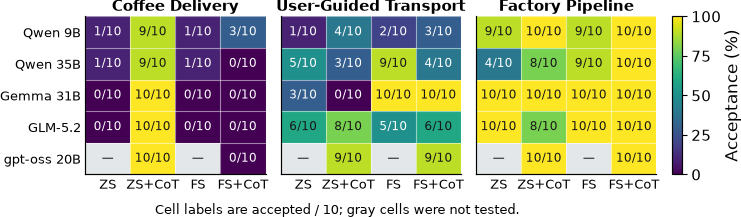

In [12]:
# Figure 3: the existing config_table is the sole source of cell values.
heatmap_labels = {"Qwen3.5-9B":"Qwen 9B","Qwen3.6-35B-A3B":"Qwen 35B","Gemma 4 31B IT":"Gemma 31B","GLM-5.2":"GLM-5.2","gpt-oss-20b":"gpt-oss 20B"}
display(config_table.pivot(index=["scenario","model"], columns="prompt", values="accepted/total")[prompt_order].reindex(pd.MultiIndex.from_product([scenario_order,model_order],names=["scenario","model"])))
fig = plt.figure(figsize=HEATMAP_SIZE)
grid = fig.add_gridspec(1, 4, width_ratios=[1,1,1,.055], left=.145, right=.985, bottom=.19, top=.81, wspace=.11)
axes = [fig.add_subplot(grid[0,i]) for i in range(3)]
short_titles = ["Coffee Delivery","User-Guided Transport","Factory Pipeline"]
for panel, (ax, scenario) in enumerate(zip(axes, scenario_order)):
    part = config_table[config_table.scenario.eq(scenario)].set_index(["model","prompt"])
    data = np.array([[part.loc[(model,prompt),"acceptance_pct"] for prompt in prompt_order] for model in model_order], dtype=float)
    ax.set_facecolor("#E4E7E9")
    im = ax.imshow(np.ma.masked_invalid(data), cmap="viridis", vmin=0, vmax=100, aspect="auto")
    ax.set_title(short_titles[panel], pad=4, weight="semibold", fontsize=11)
    ax.set_xticks(range(4), prompt_order)
    ax.set_yticks(range(5))
    ax.set_yticklabels([heatmap_labels[m] for m in model_order] if panel == 0 else [])
    ax.tick_params(axis="both", length=0, pad=3, labelsize=9.5)
    for i, model in enumerate(model_order):
        for j, prompt in enumerate(prompt_order):
            row = part.loc[(model,prompt)]
            label = "—" if pd.isna(row.total) else f"{int(row.accepted)}/{int(row.total)}"
            color = "#FFFFFF" if pd.notna(row.acceptance_pct) and row.acceptance_pct < 57 else "#171717"
            ax.text(j, i, label, ha="center", va="center", color=color, fontsize=8.5, weight="medium")
    ax.set_xticks(np.arange(-.5,4,1), minor=True)
    ax.set_yticks(np.arange(-.5,5,1), minor=True)
    ax.grid(which="minor", color="white", linewidth=.8)
    ax.tick_params(which="minor", bottom=False, left=False)
cax = fig.add_subplot(grid[0,3])
cb = fig.colorbar(im, cax=cax, ticks=[0,25,50,75,100])
cb.set_label("Acceptance (%)", labelpad=2)
fig.text(.5,.035,"Cell labels are accepted / 10; gray cells were not tested.",ha="center",fontsize=9)
save_figure(fig,"figure_acceptance",size=HEATMAP_SIZE)

prompt,FS,FS+CoT,ZS,ZS+CoT
checkpoint,,,,
Initial,44,71,32,86
Cycle 1,53,73,39,102
Cycle 2,60,81,43,111
Cycle 3,64,83,45,115
Cycle 4,66,84,49,117
Cycle 5,66,85,50,118


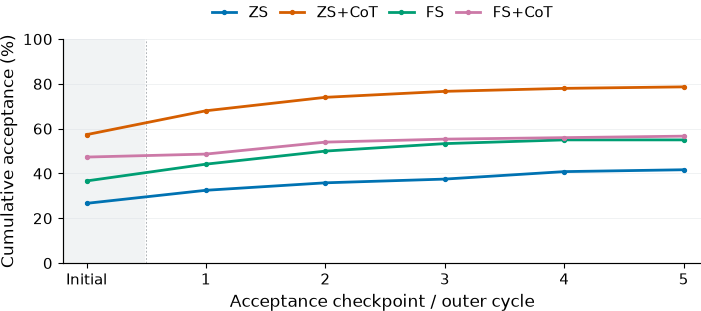

In [13]:
# Figure 4a: fixed denominators from recovery_df; cycle-level additions appear in the next figure.
display(recovery_df.pivot(index="checkpoint",columns="prompt",values="cumulative").reindex(["Initial","Cycle 1","Cycle 2","Cycle 3","Cycle 4","Cycle 5"]))
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.09,right=.99,bottom=.22,top=.78)
ax.axvspan(-.2,.48,color="#F1F3F4",zorder=0)
for prompt in prompt_order:
    rows = recovery_df[recovery_df.prompt.eq(prompt)]
    ax.plot(range(6),rows.acceptance_pct.to_numpy(),marker="o",markersize=2.8,color=PROMPT_COLORS[prompt],label=prompt,zorder=3)
ax.axvline(.5,color="#A9AEB2",lw=.65,ls=(0,(2,2)))

ax.set_xticks(range(6),["Initial","1","2","3","4","5"])
ax.set_xlabel("Acceptance checkpoint / outer cycle")
ax.set_ylabel("Cumulative acceptance (%)")
ax.set_xlim(-.2,5.15); ax.set_ylim(0,100)
ax.grid(axis="y",color="#D9DEE2",lw=.55)
ax.set_axisbelow(True)
ax.legend(ncol=4,loc="lower center",bbox_to_anchor=(.5,1.02),frameon=False,columnspacing=.75,handlelength=1.6)
save_figure(fig,"figure_recovery")

,accepted,unmetered_repair_calls,recorded_generation_output,output_per_accepted
prompt,,,,
ZS,50,204,164819.0,3296.380000
ZS+CoT,89,0,566861.0,6369.224719
FS,66,113,63012.0,954.727273
FS+CoT,66,0,897014.0,13591.121212


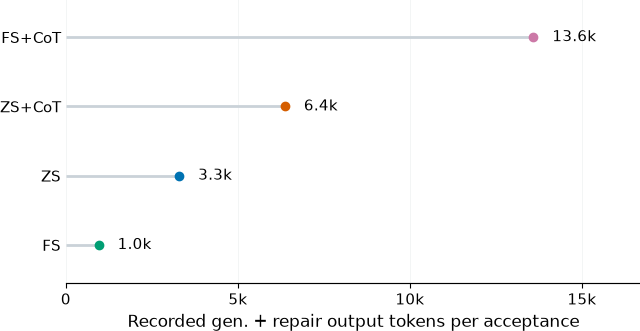

In [14]:
# Figure 4b: four shared models; numerator includes available usage from failed runs.
display(shared_effort[["accepted","unmetered_repair_calls","recorded_generation_output","output_per_accepted"]])
ordered = shared_effort.sort_values("output_per_accepted")
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.14,right=.95,bottom=.25,top=.96)
y = np.arange(len(ordered))
for i,(prompt,row) in enumerate(ordered.iterrows()):
    value = row.output_per_accepted
    ax.hlines(i,0,value,color="#CAD2D8",lw=2,zorder=1)
    ax.plot(value,i,"o",ms=6,color=PROMPT_COLORS[prompt],zorder=2)
    ax.text(value+550,i,f"{value/1000:.1f}k",va="center",fontsize=11)
ax.set_yticks(y,ordered.index)
ax.set_xlim(0,ordered.output_per_accepted.max()*1.23)
ax.set_ylim(-.55,len(y)-.45)
ax.set_xlabel("Recorded gen. + repair output tokens per acceptance")
ax.set_xticks([0,5000,10000,15000],["0","5k","10k","15k"])
ax.grid(axis="x",color="#E2E5E7",lw=.55)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y",length=0)
save_figure(fig,"figure_effort")

## Terminal outcomes by scenario

This figure partitions each scenario's 180 runs by the recorded terminal stage. Internal UPPAAL verification and adapted scenario-property verification are separate. A terminal stage identifies where the workflow stopped, not the underlying root cause.

terminal_stage,Accepted,Generation / compilation,XML export,Internal verification,Scenario properties
scenario,,,,,
Coffee Delivery,55,25,5,91,4
User-Guided Transport,97,5,53,0,25
Factory Pipeline,167,3,3,4,3


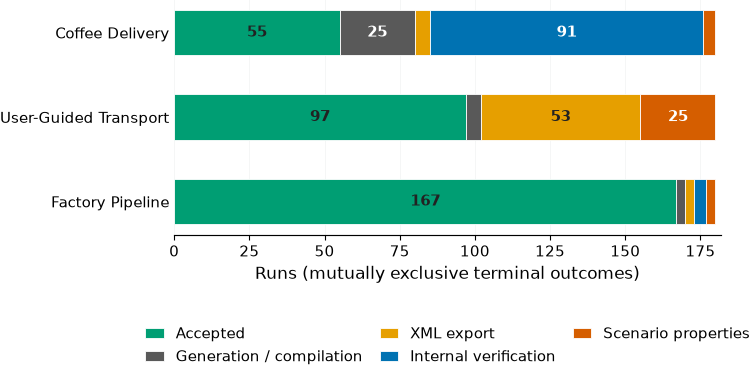

In [15]:
stage_display = {"accepted":"Accepted","dsl_generation":"Generation / compilation","xml_export":"XML export","verifyta_internal":"Internal verification","verifyta_adapted":"Scenario properties"}
stage_keys = list(stage_display)
stage_counts = runs_df.groupby(["scenario","terminal_stage"]).size().unstack(fill_value=0).reindex(index=scenario_order,columns=stage_keys,fill_value=0)
display(stage_counts.rename(columns=stage_display))
assert stage_counts.sum(axis=1).eq(runs_df.groupby("scenario").size().reindex(scenario_order)).all()
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.21,right=.98,bottom=.33,top=.92)
y = np.arange(len(scenario_order))
left = np.zeros(len(scenario_order))
for stage in stage_keys:
    values = stage_counts[stage].to_numpy()
    bars = ax.barh(y,values,left=left,height=.54,color=STAGE_COLORS[stage],label=stage_display[stage],edgecolor="white",linewidth=.6)
    for i,value in enumerate(values):
        if value >= 9:
            ax.text(left[i]+value/2,i,str(value),ha="center",va="center",fontsize=11,color="white" if stage in ("dsl_generation","verifyta_internal","verifyta_adapted") else "#222222",weight="semibold")
    left += values
ax.set_yticks(y,scenario_order); ax.invert_yaxis()
ax.set_xlim(0,max(left)*1.01)
ax.set_xlabel("Runs (mutually exclusive terminal outcomes)")
ax.grid(axis="x",color="#E3E6E8",lw=.5); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y",length=0)
ax.legend(ncol=3,loc="upper center",bbox_to_anchor=(.5,-.33),frameon=False,columnspacing=1.1,handlelength=1.2)
save_figure(fig,"figure_failure_stages")

## Recorded output-token decomposition

The three scenario groups each contain 180 runs, so per-run token volume is directly comparable. Tokens from specification generation, compiler repair, and candidate-dependent query adaptation are shown separately. The 317 repair responses without usage remain unmetered; this is recorded output-token volume, not latency or monetary cost.

kind,Generation,Compiler repair,Query adaptation,adaptation_share_pct,unmetered_repair_calls
scenario,,,,,
Coffee Delivery,4780.7,552.1,15965.7,75.0,228
User-Guided Transport,1748.7,471.7,10239.8,82.2,43
Factory Pipeline,2491.0,454.4,6777.0,69.7,46


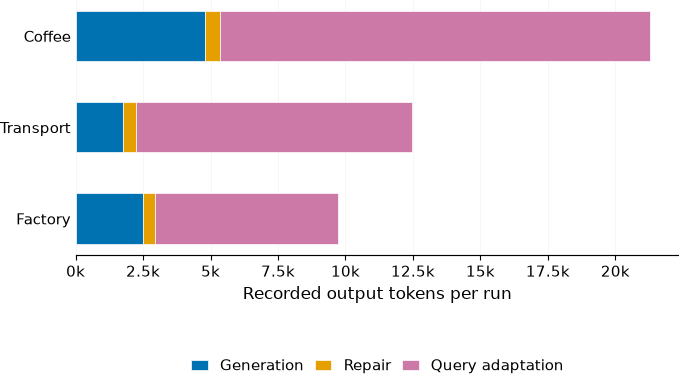

In [16]:
scenario_lookup = runs_df.set_index("run_key").scenario
calls_for_plot = llm_calls_df.assign(scenario=llm_calls_df.run_key.map(scenario_lookup))
token_totals = calls_for_plot.groupby(["scenario","kind"]).output_tokens.sum(min_count=1).unstack(fill_value=0).reindex(index=scenario_order,columns=["generate","repair","query_adaptation"],fill_value=0)
run_denominator = runs_df.groupby("scenario").size().reindex(scenario_order)
tokens_per_run = token_totals.div(run_denominator,axis=0)
unmetered_by_scenario = calls_for_plot[~calls_for_plot.usage_available].groupby("scenario").size().reindex(scenario_order,fill_value=0)
adaptation_share = 100*tokens_per_run.query_adaptation/tokens_per_run.sum(axis=1)
display(tokens_per_run.rename(columns={"generate":"Generation","repair":"Compiler repair","query_adaptation":"Query adaptation"}).round(1).assign(adaptation_share_pct=adaptation_share.round(1),unmetered_repair_calls=unmetered_by_scenario))
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.13,right=.98,bottom=.31,top=.95)
short_scenarios = ["Coffee","Transport","Factory"]
y = np.arange(3); left = np.zeros(3)
for kind,label in [("generate","Generation"),("repair","Repair"),("query_adaptation","Query adaptation")]:
    values = tokens_per_run[kind].to_numpy()
    ax.barh(y,values,left=left,height=.55,color=TOKEN_COLORS[kind],label=label,edgecolor="white",linewidth=.5)
    left += values
ax.set_yticks(y,short_scenarios); ax.invert_yaxis()
ax.set_xlabel("Recorded output tokens per run")
ax.set_xlim(0,max(left)*1.05)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f"{x/1000:g}k"))
ax.grid(axis="x",color="#E3E6E8",lw=.5); ax.set_axisbelow(True)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y",length=0)
ax.legend(ncol=3,loc="upper center",bbox_to_anchor=(.5,-.35),frameon=False,columnspacing=.7,handlelength=1.1)
save_figure(fig,"figure_effort_decomposition")

## Recovery and recorded effort across cycles

The cycle-level summary is rendered as two separate figures on the same 7.1 × 2.55 inch canvas used throughout the notebook. The recovery figure shows runs reaching each cycle and newly accepted runs. The effort figure attributes recorded generation/repair and query-adaptation output tokens to the cycle in which calls occurred. Missing repair usage makes token totals lower bounds. These figures describe observed recovery without a budget-matched unguided control.

,reached,newly_accepted,generation_repair,query_adaptation,unmetered_repair_calls
cycle,,,,,
1,540,267,975941.0,2632656.0,257
2,190,28,285492.0,1041053.0,47
3,155,12,243424.0,822238.0,8
4,141,9,220521.0,738518.0,1
5,131,3,164390.0,702385.0,4


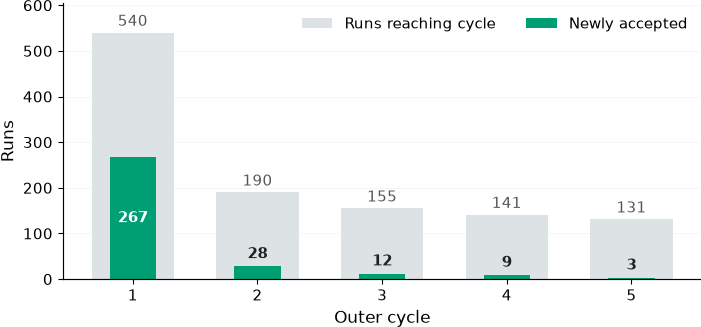

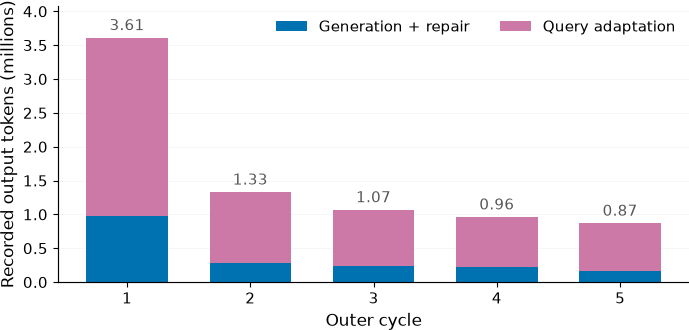

In [17]:
cycle_counts = cycles_df.groupby("cycle").agg(reached=("run_key","size"),newly_accepted=("reconstructed_accepted","sum")).reindex(range(1,6))
cycle_tokens = llm_calls_df.assign(group=np.where(llm_calls_df.kind.eq("query_adaptation"),"query_adaptation","generation_repair")).groupby(["cycle","group"]).output_tokens.sum().unstack(fill_value=0).reindex(range(1,6),fill_value=0)
cycle_missing = llm_calls_df[~llm_calls_df.usage_available].groupby("cycle").size().reindex(range(1,6),fill_value=0)
cycle_summary = cycle_counts.join(cycle_tokens).assign(unmetered_repair_calls=cycle_missing)
display(cycle_summary)
assert cycle_summary.reached.sum() == len(cycles_df)
assert cycle_summary.newly_accepted.sum() == runs_df.accepted.sum()
x = np.arange(1,6)

# Separate figure: runs reaching each cycle and observed recoveries.
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.09,right=.99,bottom=.24,top=.93)
ax.bar(x,cycle_summary.reached,width=.66,color="#DDE2E5",label="Runs reaching cycle")
ax.bar(x,cycle_summary.newly_accepted,width=.37,color=STAGE_COLORS["accepted"],label="Newly accepted")
for n,reached,accepted in zip(x,cycle_summary.reached,cycle_summary.newly_accepted):
    ax.text(n,reached+7,str(reached),ha="center",va="bottom",fontsize=11,color="#555555")
    ax.text(n,accepted/2 if accepted>=40 else accepted+10,str(accepted),ha="center",va="center" if accepted>=40 else "bottom",fontsize=11,weight="semibold",color="white" if accepted>=40 else "#222222")
ax.set_ylim(0,cycle_summary.reached.max()*1.12)
ax.set_ylabel("Runs")
ax.set_xlabel("Outer cycle")
ax.set_xticks(x,[str(i) for i in x])
ax.legend(ncol=2,loc="upper right",frameon=False)
ax.grid(axis="y",color="#E5E8EA",lw=.5)
ax.set_axisbelow(True)
save_figure(fig,"figure_cycle_recovery")

# Separate figure: recorded output-token volume incurred within each cycle.
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
fig.subplots_adjust(left=.1,right=.99,bottom=.24,top=.93)
generation_values = cycle_summary.generation_repair/1e6
adaptation_values = cycle_summary.query_adaptation/1e6
ax.bar(x,generation_values,width=.66,color="#0072B2",label="Generation + repair")
ax.bar(x,adaptation_values,width=.66,bottom=generation_values,color=TOKEN_COLORS["query_adaptation"],label="Query adaptation")
for n,total in zip(x,generation_values+adaptation_values):
    ax.text(n,total+.06,f"{total:.2f}",ha="center",va="bottom",fontsize=11,color="#555555")
ax.set_ylim(0,(generation_values+adaptation_values).max()*1.13)
ax.set_ylabel("Recorded output tokens (millions)")
ax.set_xlabel("Outer cycle")
ax.set_xticks(x,[str(i) for i in x])
ax.legend(ncol=2,loc="upper right",frameon=False)
ax.grid(axis="y",color="#E5E8EA",lw=.5)
ax.set_axisbelow(True)
save_figure(fig,"figure_cycle_effort")

## Manuscript table exports

The same reconstructed DataFrames drive the tables and plots. These exports use booktabs rules, concise headings, and consistent precision. The long configuration listing is most suitable for supplementary material; the compact matrix retains unavailable cells. No values are manually inserted into LaTeX.

**Figure selection.** The terminal-outcome chart, separate cycle recovery and cycle effort charts, and scenario effort decomposition each add a distinct view of the workflow. A 54-point reliability/efficiency scatter would require a dense legend and would largely repeat the configuration matrix. Query outcomes are already tabulated above; a proportional chart would obscure the fact that query occurrences are neither independent runs nor a semantic-accuracy measure.

In [18]:
def write_ieee_table(frame, name, caption, label, *, wide=False, **kwargs):
    tex = frame.reset_index().to_latex(index=False, caption=caption, label=label, escape=True, **kwargs)
    if wide:
        tex = tex.replace("\\begin{table}", "\\begin{table*}").replace("\\end{table}", "\\end{table*}")
    (PLOTS / name).write_text(tex, encoding="utf-8")
    return frame

outcome_print = scenario_outcomes.rename(columns={"accepted":"Accepted","generation/compilation":"Gen./comp.","export":"Export","verification":"Verification","total":"Runs","acceptance_pct":"Accepted (%)"}).loc[scenario_order]
outcome_print.columns.name = None
outcome_print.index.name = "Scenario"
display(outcome_print)
write_ieee_table(outcome_print,"table_final_outcomes.tex","Final run outcomes by scenario; failures are mutually exclusive terminal stages.","tab:final-outcomes",float_format="%.1f")

matrix_print = matrix_table.reindex(pd.MultiIndex.from_product([scenario_order,model_order],names=["scenario","model"]))[prompt_order].replace("—","--")
matrix_print.columns.name = None
matrix_print.index.names = ["Scenario","Model"]
display(matrix_print)
write_ieee_table(matrix_print,"table_experimental_matrix.tex","Accepted runs out of ten repetitions in each tested configuration; -- denotes unavailable.","tab:matrix")

config_print = config_table[config_table.total.notna()][["scenario","model","prompt","accepted","total","acceptance_pct"]].copy()
config_print.columns = ["Scenario","Model","Prompt","Accepted","Runs","Accepted (%)"]
config_print["Accepted"] = config_print["Accepted"].astype(int)
config_print["Runs"] = config_print["Runs"].astype(int)
display(config_print.head(12))
config_print.to_latex(PLOTS/"table_configuration_acceptance.tex",index=False,longtable=True,caption="Configuration-level acceptance for all tested combinations.",label="tab:config-detail",float_format="%.1f")

recovery_print = recovery_df.pivot(index="prompt",columns="checkpoint",values="cumulative").reindex(prompt_order)[["Initial","Cycle 1","Cycle 2","Cycle 3","Cycle 4","Cycle 5"]]
recovery_print.insert(0,"Runs",recovery_df.groupby("prompt").runs.first().reindex(prompt_order))
recovery_print.columns.name = None
recovery_print.index.name = "Prompt"
display(recovery_print)
write_ieee_table(recovery_print,"table_recovery.tex","Cumulative accepted runs at fixed-denominator checkpoints.","tab:recovery")

effort_print = effort_table[["runs","accepted","generation_calls","repair_calls","query_calls","recorded_generation_output","query_output","unmetered_repair_calls"]].copy()
effort_print.columns = ["Runs","Accepted","Gen. calls","Repair calls","Query calls","Gen.+repair output","Query output","Unmetered repairs"]
effort_print = effort_print.astype(int)
effort_print.columns.name = None
effort_print.index.name = "Prompt"
display(effort_print)
write_ieee_table(effort_print,"table_computational_effort.tex","Recorded LLM effort by prompting configuration; output is tokens and excludes missing repair usage.","tab:effort",wide=True)
assert outcome_print["Runs"].sum() == len(runs_df)
assert recovery_print["Cycle 5"].sum() == runs_df.accepted.sum()

,Accepted,Gen./comp.,Export,Verification,Runs,Accepted (%)
Scenario,,,,,,
Coffee Delivery,55,25,5,95,180,30.555556
User-Guided Transport,97,5,53,25,180,53.888889
Factory Pipeline,167,3,3,7,180,92.777778


ZS ZS+CoT     FS FS+CoT
Scenario              Model                                      
Coffee Delivery       Qwen3.5-9B        1/10   9/10   1/10   3/10
                      Qwen3.6-35B-A3B   1/10   9/10   1/10   0/10
                      Gemma 4 31B IT    0/10  10/10   0/10   0/10
                      GLM-5.2           0/10  10/10   0/10   0/10
                      gpt-oss-20b         --  10/10     --   0/10
User-Guided Transport Qwen3.5-9B        1/10   4/10   2/10   3/10
                      Qwen3.6-35B-A3B   5/10   3/10   9/10   4/10
                      Gemma 4 31B IT    3/10   0/10  10/10  10/10
                      GLM-5.2           6/10   8/10   5/10   6/10
                      gpt-oss-20b         --   9/10     --   9/10
Factory Pipeline      Qwen3.5-9B        9/10  10/10   9/10  10/10
                      Qwen3.6-35B-A3B   4/10   8/10   9/10  10/10
                      Gemma 4 31B IT   10/10  10/10  10/10  10/10
                      GLM-5.2          10/10   8/10  10/10  10/10
                      gpt-oss-20b         --  10/10     --  10/10

,Scenario,Model,Prompt,Accepted,Runs,Accepted (%)
0,Coffee Delivery,Qwen3.5-9B,ZS,1,10,10.0
1,Coffee Delivery,Qwen3.5-9B,ZS+CoT,9,10,90.0
2,Coffee Delivery,Qwen3.5-9B,FS,1,10,10.0
3,Coffee Delivery,Qwen3.5-9B,FS+CoT,3,10,30.0
4,Coffee Delivery,Qwen3.6-35B-A3B,ZS,1,10,10.0
5,Coffee Delivery,Qwen3.6-35B-A3B,ZS+CoT,9,10,90.0
6,Coffee Delivery,Qwen3.6-35B-A3B,FS,1,10,10.0
7,Coffee Delivery,Qwen3.6-35B-A3B,FS+CoT,0,10,0.0
8,Coffee Delivery,Gemma 4 31B IT,ZS,0,10,0.0
9,Coffee Delivery,Gemma 4 31B IT,ZS+CoT,10,10,100.0


,Runs,Initial,Cycle 1,Cycle 2,Cycle 3,Cycle 4,Cycle 5
Prompt,,,,,,,
ZS,120,32,39,43,45,49,50
ZS+CoT,150,86,102,111,115,117,118
FS,120,44,53,60,64,66,66
FS+CoT,150,71,73,81,83,84,85


,Runs,Accepted,Gen. calls,Repair calls,Query calls,Gen.+repair output,Query output,Unmetered repairs
Prompt,,,,,,,,
ZS,120,50,291,503,252,164819,1513151,204
ZS+CoT,150,118,229,34,210,647963,1506275,0
FS,120,66,269,290,246,63012,1087005,113
FS+CoT,150,85,371,49,355,1013974,1830419,0


## Reconciliation with manuscript comparison targets

The target dictionary below is used only here. A mismatch remains a mismatch: it does not alter the normalized records or figures. For effort, 317 completed repair responses appear in `llm_responses.jsonl` but have no matching `llm_call_history` entry and no raw token usage. The response-log call count matches the manuscript target; the recorded generation/repair output total is 33,458 tokens below its target. The notebook cannot infer exact usage for those 317 calls from response text. Ratios based on available usage are lower bounds. The history and telemetry agree with each other, and affected source files are displayed above. The table and diagnostic cells identify affected source records where the two accounting methods differ.

In [19]:
reported = {"runs":540,"executed cycles":1157,"accepted runs":319,"unsuccessful runs":221,"generation/compilation terminations":33,"export terminations":61,"verification terminations":127,"Coffee Delivery acceptances":55,"User-Guided Transport acceptances":97,"Factory Pipeline acceptances":167,"initial-candidate acceptances":233,"first-cycle cumulative acceptances":267,"final cumulative acceptances":319,"additional cycle 2":28,"additional cycle 3":12,"additional cycle 4":9,"additional cycle 5":3,"completed generation/repair calls":2036,"generation/repair output tokens":1923226,"query-adaptation calls":1063,"query-adaptation output tokens":5936850,"returned adapted-query probability intervals":10913,"aborted-query occurrences":5383,"verifier-error entries":181,"measured probability mismatches":120}
all_recovery = recovery_df.groupby("checkpoint")[["cumulative","additional"]].sum()
scenario_accept = runs_df.groupby("scenario").accepted.sum()
actual = {"runs":len(runs_df),"executed cycles":len(cycles_df),"accepted runs":int(runs_df.accepted.sum()),"unsuccessful runs":int((~runs_df.accepted).sum()),"generation/compilation terminations":int(overall_outcomes["generation/compilation"]),"export terminations":int(overall_outcomes["export"]),"verification terminations":int(overall_outcomes["verification"]),"Coffee Delivery acceptances":int(scenario_accept["Coffee Delivery"]),"User-Guided Transport acceptances":int(scenario_accept["User-Guided Transport"]),"Factory Pipeline acceptances":int(scenario_accept["Factory Pipeline"]),"initial-candidate acceptances":int(runs_df.initial_accepted.sum()),"first-cycle cumulative acceptances":int(all_recovery.loc["Cycle 1","cumulative"]),"final cumulative acceptances":int(runs_df.accepted.sum()),"completed generation/repair calls":int(llm_calls_df.kind.isin(["generate","repair"]).sum()),"generation/repair output tokens":int(llm_calls_df.loc[llm_calls_df.kind.isin(["generate","repair"]),"output_tokens"].sum()),"query-adaptation calls":int(llm_calls_df.kind.eq("query_adaptation").sum()),"query-adaptation output tokens":int(llm_calls_df.loc[llm_calls_df.kind.eq("query_adaptation"),"output_tokens"].sum()),"returned adapted-query probability intervals":int(queries_df.query("verification_path == 'scenario' and has_interval").shape[0]),"aborted-query occurrences":int(queries_df.query("verification_path == 'scenario' and failure_kind == 'aborted'").shape[0]),"verifier-error entries":int(queries_df.query("verification_path == 'scenario' and failure_kind == 'verifyta_error'").shape[0]),"measured probability mismatches":int(queries_df.query("verification_path == 'scenario' and failure_kind == 'probability_delta' and has_interval").shape[0])}
for n in range(2,6): actual[f"additional cycle {n}"] = int(all_recovery.loc[f"Cycle {n}","additional"])
reconciliation = pd.DataFrame({"metric":list(reported),"previously_reported":[reported[k] for k in reported],"reconstructed":[actual[k] for k in reported]})
reconciliation["difference"] = reconciliation.reconstructed - reconciliation.previously_reported
reconciliation["match"] = reconciliation.difference.eq(0)
display(reconciliation)
print("Mismatches:", int((~reconciliation.match).sum()))
call_history_vs_telemetry = pd.DataFrame([{"source_file":str(p.relative_to(ROOT)),"history_calls":len(d.get("llm_call_history") or []),"telemetry_calls":(d.get("telemetry") or {}).get("llm_calls",0),"history_output":sum((c.get("completion_tokens") or 0) for c in d.get("llm_call_history") or []),"telemetry_output":(d.get("telemetry") or {}).get("completion_tokens_total",0)} for p,d in cycle_raw.items()])
affected = call_history_vs_telemetry.query("history_calls != telemetry_calls or history_output != telemetry_output")
print("Cycle files with history/telemetry disagreement:",len(affected)); display(affected.head(20))
display(llm_calls_df.groupby("kind").agg(calls=("kind","size"),output_tokens=("output_tokens","sum")))
assert len(affected) == 0
assert reconciliation.set_index("metric").loc["runs","match"]

,metric,previously_reported,reconstructed,difference,match
0,runs,540,540,0,True
1,executed cycles,1157,1157,0,True
2,accepted runs,319,319,0,True
3,unsuccessful runs,221,221,0,True
4,generation/compilation terminations,33,33,0,True
5,export terminations,61,61,0,True
6,verification terminations,127,127,0,True
7,Coffee Delivery acceptances,55,55,0,True
8,User-Guided Transport acceptances,97,97,0,True
9,Factory Pipeline acceptances,167,167,0,True


Mismatches: 1
Cycle files with history/telemetry disagreement: 0


,source_file,history_calls,telemetry_calls,history_output,telemetry_output


,calls,output_tokens
kind,,
generate,1160,1623671.0
query_adaptation,1063,5936850.0
repair,876,266097.0
